# Init

In [1]:
import sys
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

from spectraderma_processor import SpectraDermaProcessor

mpl.rcParams['font.family'] = 'arial'
mpl.rcParams['font.size'] = 10

colors = [
    '#8686D2',
    '#7BAED3',
    '#9CCBA0',
    '#E6DC84',
    '#D47291',
    '#868686',
]

In [2]:
# Initialize processor
processor = SpectraDermaProcessor(sample_rate=50.0)

# 555S2

In [41]:
processor.load_data('../data/spectraderama_data_2025-04-02_sattac555S2.csv')

# Get raw data for reference
timestamp, channels = processor.get_data()
print(f"Loaded data shape: {channels.shape}")
print(f"First few rows:")
print(pd.DataFrame(channels[:5]))  # Show first few rows like data.head()

Loaded data shape: (390025, 6)
First few rows:
     0    1    2    3    4    5
0  1.0  2.0  5.0  6.0  6.0  4.0
1  1.0  2.0  5.0  6.0  6.0  4.0
2  1.0  2.0  5.0  6.0  6.0  4.0
3  1.0  2.0  5.0  6.0  6.0  4.0
4  1.0  2.0  5.0  6.0  6.0  4.0


In [42]:
# Use processor pipeline to get processed data
processor.swt_denoise(wavelet="db2", level=3, zero_levels=(1, 2, 3))
processor.bandpass_filter(low_freq=0.5, high_freq=3.0, order=3)

# Get processed data
timestamp, channels_swt_f = processor.get_data()
print(f"Processed data shape: {channels_swt_f.shape}")

Processed data shape: (390025, 6)


(-50.0, 50.0)

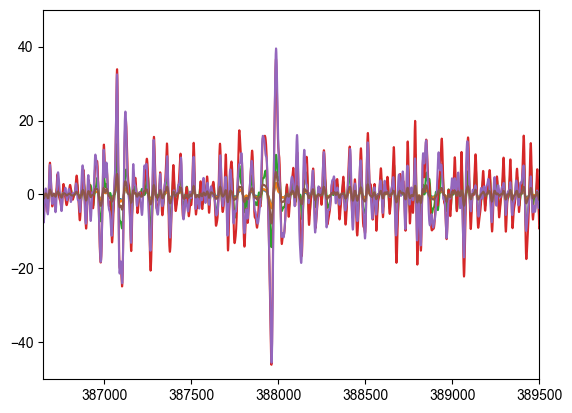

In [43]:
plt.plot(timestamp, channels_swt_f)
plt.xlim(386650, 389500)
plt.ylim(-50, 50)

In [46]:
t1 = 1500
t2 = 386650
d = 250

time_limits_1 = (t1, t1 + d)
time_limits_2 = (t2, t2 + d)

amplitude_limits = (-25, 25)

# Use processor's normalize method with both time regions
processor.normalize(time_limits_1, time_limits_2, amplitude_limits=amplitude_limits)

# Get normalized data
timestamp, channels_swt_f_normalized = processor.get_data()
print(f"Normalized data shape: {channels_swt_f_normalized.shape}")

Normalized data shape: (390025, 6)


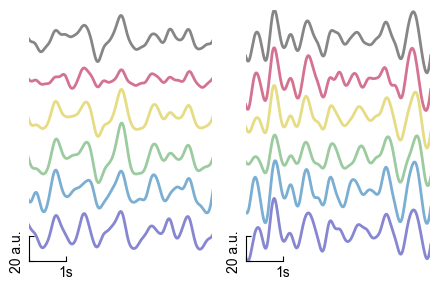

In [47]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(4.5, 3))

sample_rate = processor.sample_rate
y_offset = 30  # Small offset between channels

# Left subplot - first time region
ax_left = axes[0]
for i in range(channels_swt_f_normalized.shape[1]):
    y = channels_swt_f_normalized[:, i] + i * y_offset
    ax_left.plot(timestamp, y, color=colors[i], alpha=1, linewidth=2)

ax_left.set_xlim(*time_limits_1)
ax_left.set_ylim(amplitude_limits[0], amplitude_limits[1] + 5 * y_offset)

# Set spine bounds to show only scale bar segments
# Bottom spine: show only 1 second (30 samples)
ax_left.spines['bottom'].set_bounds(time_limits_1[0], time_limits_1[0] + sample_rate)
# Left spine: show only 20 units
ax_left.spines['left'].set_bounds(amplitude_limits[0], amplitude_limits[0] + 20)

# Hide top and right spines
ax_left.spines['top'].set_visible(False)
ax_left.spines['right'].set_visible(False)

# Set custom ticks for the scale bars
ax_left.set_xticks([time_limits_1[0], time_limits_1[0] + sample_rate])
ax_left.set_xticklabels(['', '1s'])
ax_left.set_yticks([amplitude_limits[0], amplitude_limits[0] + 20])
ax_left.set_yticklabels(['', '20 a.u.'], rotation=90)

ax_left.tick_params(axis='both', which='both', direction='in')

# Right subplot - second time region
ax_right = axes[1]
for i in range(channels_swt_f_normalized.shape[1]):
    y = channels_swt_f_normalized[:, i] + i * y_offset
    ax_right.plot(timestamp, y, color=colors[i], alpha=1, linewidth=2)

ax_right.set_xlim(*time_limits_2)
ax_right.set_ylim(amplitude_limits[0], amplitude_limits[1] + 5 * y_offset)

# Set spine bounds to show only scale bar segments
# Bottom spine: show only 1 second (30 samples)
ax_right.spines['bottom'].set_bounds(time_limits_2[0], time_limits_2[0] + sample_rate)
# Left spine: show only 20 units
ax_right.spines['left'].set_bounds(amplitude_limits[0], amplitude_limits[0] + 20)

# Hide top and right spines
ax_right.spines['top'].set_visible(False)
ax_right.spines['right'].set_visible(False)

# Set custom ticks for the scale bars
ax_right.set_xticks([time_limits_2[0], time_limits_2[0] + sample_rate])
ax_right.set_xticklabels(['', '1s'])
ax_right.set_yticks([amplitude_limits[0], amplitude_limits[0] + 20])
ax_right.set_yticklabels(['', '20 a.u.'], rotation=90)

ax_right.tick_params(axis='both', which='both', direction='in')

plt.tight_layout()
# plt.savefig('../figures/fig1/mode_a_sample.png', dpi=600, bbox_inches='tight')
plt.show()


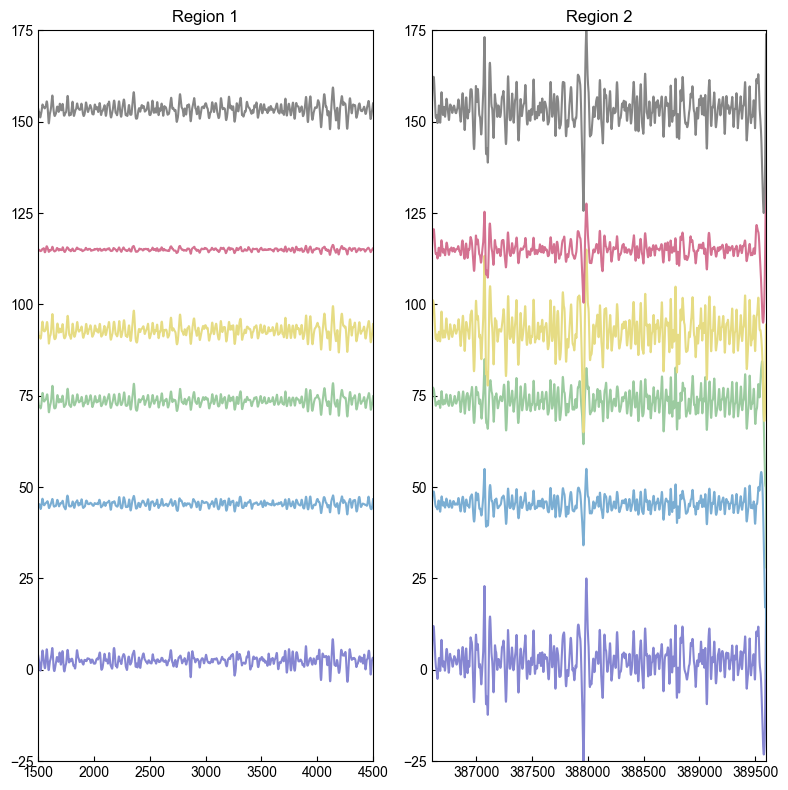

In [50]:
ppg_region_start_1 = 1500
ppg_region_end_1 = 4500

ppg_region_start_2 = 386600
ppg_region_end_2 = 389600

ppg_region_1 = (ppg_region_start_1, ppg_region_end_1)
ppg_region_2 = (ppg_region_start_2, ppg_region_end_2)

amplitude_limits = (-25, 25)

processor.normalize(ppg_region_1, ppg_region_2, amplitude_limits=amplitude_limits)
timestamp, channels_swt_f_normalized = processor.get_data()

y_offset = 30  # Small offset between channels

fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(8, 8))

for ch in range(channels_swt_f_normalized.shape[1]):
    y = channels_swt_f_normalized[:, ch] + ch * y_offset
    ax1.plot(timestamp, y, color=colors[ch], linewidth=1.5)
    ax2.plot(timestamp, y, color=colors[ch], linewidth=1.5)

ax1.set_xlim(*ppg_region_1)
ax2.set_xlim(*ppg_region_2)

ax1.set_ylim(amplitude_limits[0], amplitude_limits[1] + 5 * y_offset)
ax2.set_ylim(amplitude_limits[0], amplitude_limits[1] + 5 * y_offset)

ax1.set_title("Region 1")
ax2.set_title("Region 2")

for ax in (ax1, ax2):
    ax.tick_params(direction='in')

plt.tight_layout()
plt.show()

# 520S2

In [3]:
processor.load_data('../data/spectraderama_data_2025-03-25_sattac520S2.csv')

# Get raw data for reference
timestamp, channels = processor.get_data()
print(f"Loaded data shape: {channels.shape}")
print(f"First few rows:")
print(pd.DataFrame(channels[:5]))  # Show first few rows like data.head()

Loaded data shape: (426807, 6)
First few rows:
      0     1     2      3      4     5
0  29.0  32.0  83.0  277.0  465.0  78.0
1  29.0  32.0  83.0  277.0  465.0  78.0
2  28.0  31.0  80.0  267.0  448.0  76.0
3  28.0  31.0  80.0  267.0  447.0  75.0
4  28.0  31.0  80.0  267.0  449.0  75.0


In [4]:
# Use processor pipeline to get processed data
processor.swt_denoise(wavelet="db2", level=3, zero_levels=(1, 2, 3))
processor.bandpass_filter(low_freq=0.5, high_freq=3.0, order=3)

# Get processed data
timestamp, channels_swt_f = processor.get_data()
print(f"Processed data shape: {channels_swt_f.shape}")

Processed data shape: (426807, 6)


In [5]:
t1 = 250
t2 = 423000
d = 500

time_limits_1 = (t1, t1 + d)
time_limits_2 = (t2, t2 + d)

amplitude_limits = (-25, 25)

# Use processor's normalize method with both time regions
processor.normalize(time_limits_1, time_limits_2, amplitude_limits=amplitude_limits)

# Get normalized data
timestamp, channels_swt_f_normalized = processor.get_data()
print(f"Normalized data shape: {channels_swt_f_normalized.shape}")

Normalized data shape: (426807, 6)


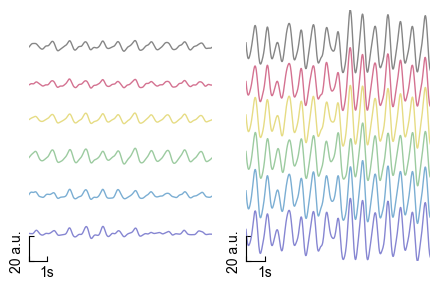

In [6]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(4.5, 3))

sample_rate = processor.sample_rate
y_offset = 30  # Small offset between channels

# Left subplot - first time region
ax_left = axes[0]
for i in range(channels_swt_f_normalized.shape[1]):
    y = channels_swt_f_normalized[:, i] + i * y_offset
    ax_left.plot(timestamp, y, color=colors[i], alpha=1, linewidth=1)

ax_left.set_xlim(*time_limits_1)
ax_left.set_ylim(amplitude_limits[0], amplitude_limits[1] + 5 * y_offset)

# Set spine bounds to show only scale bar segments
# Bottom spine: show only 1 second (50 samples)
ax_left.spines['bottom'].set_bounds(time_limits_1[0], time_limits_1[0] + sample_rate)
# Left spine: show only 20 units
ax_left.spines['left'].set_bounds(amplitude_limits[0], amplitude_limits[0] + 20)

# Hide top and right spines
ax_left.spines['top'].set_visible(False)
ax_left.spines['right'].set_visible(False)

# Set custom ticks for the scale bars
ax_left.set_xticks([time_limits_1[0], time_limits_1[0] + sample_rate])
ax_left.set_xticklabels(['', '1s'])
ax_left.set_yticks([amplitude_limits[0], amplitude_limits[0] + 20])
ax_left.set_yticklabels(['', '20 a.u.'], rotation=90)

ax_left.tick_params(axis='both', which='both', direction='in')

# Right subplot - second time region
ax_right = axes[1]
for i in range(channels_swt_f_normalized.shape[1]):
    y = channels_swt_f_normalized[:, i] + i * y_offset
    ax_right.plot(timestamp, y, color=colors[i], alpha=1, linewidth=1)

ax_right.set_xlim(*time_limits_2)
ax_right.set_ylim(amplitude_limits[0], amplitude_limits[1] + 5 * y_offset)

# Set spine bounds to show only scale bar segments
# Bottom spine: show only 1 second (50 samples)
ax_right.spines['bottom'].set_bounds(time_limits_2[0], time_limits_2[0] + sample_rate)
# Left spine: show only 20 units
ax_right.spines['left'].set_bounds(amplitude_limits[0], amplitude_limits[0] + 20)

# Hide top and right spines
ax_right.spines['top'].set_visible(False)
ax_right.spines['right'].set_visible(False)

# Set custom ticks for the scale bars
ax_right.set_xticks([time_limits_2[0], time_limits_2[0] + sample_rate])
ax_right.set_xticklabels(['', '1s'])
ax_right.set_yticks([amplitude_limits[0], amplitude_limits[0] + 20])
ax_right.set_yticklabels(['', '20 a.u.'], rotation=90)

ax_right.tick_params(axis='both', which='both', direction='in')

plt.tight_layout()
# plt.savefig('../figures/fig1/mode_a_sample.png', dpi=600, bbox_inches='tight')
plt.show()


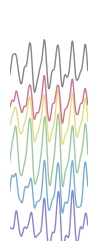

In [7]:
amplitude_limits = (-5, 30)

y_offset = 5

fig, ax = plt.subplots(figsize=(1, 3))

for i in range(channels_swt_f_normalized.shape[1]):
    y = channels_swt_f_normalized[:, i] + i * y_offset
    ax.plot(timestamp, y, color=colors[i], alpha=1, linewidth=1)

ax.set_xlim(time_limits_1[0], time_limits_1[1] - 250)
ax.set_ylim(*amplitude_limits)

ax.set_axis_off()
# plt.savefig('../figures/fig3/diagram/mwppg_example.png', dpi=600, bbox_inches='tight', pad_inches=0)
plt.show()

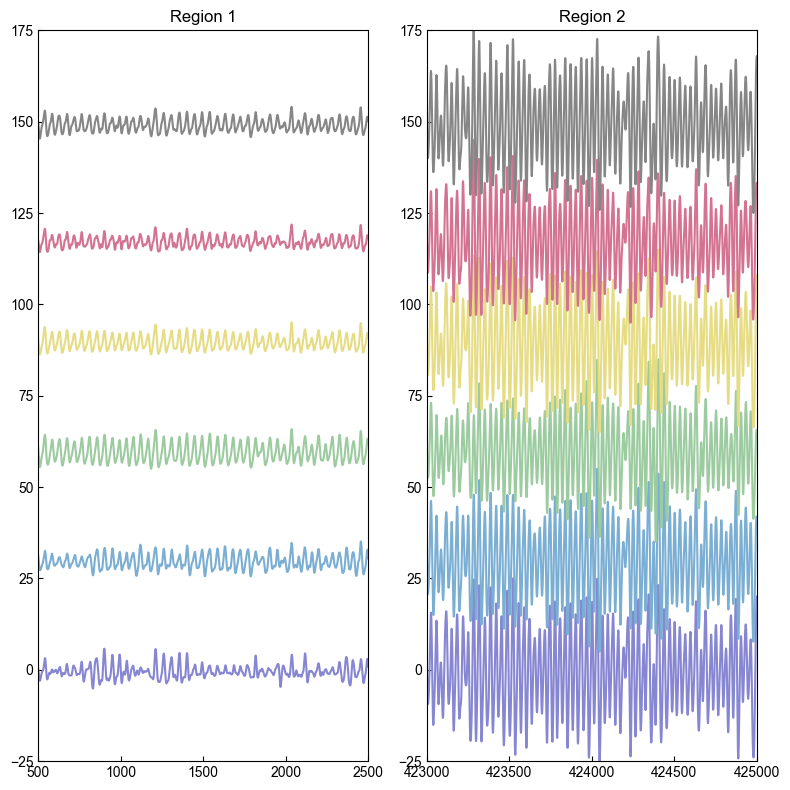

In [8]:
ppg_region_start_1 = 500
ppg_region_end_1 = 2500

ppg_region_start_2 = 423000
ppg_region_end_2 = 425000

ppg_region_1 = (ppg_region_start_1, ppg_region_end_1)
ppg_region_2 = (ppg_region_start_2, ppg_region_end_2)

amplitude_limits = (-25, 25)

processor.normalize(ppg_region_1, ppg_region_2, amplitude_limits=amplitude_limits)
timestamp, channels_swt_f_normalized = processor.get_data()

sample_rate = 30.0
y_offset = 30  # Small offset between channels

fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(8, 8))

for ch in range(channels_swt_f_normalized.shape[1]):
    y = channels_swt_f_normalized[:, ch] + ch * y_offset
    ax1.plot(timestamp, y, color=colors[ch], linewidth=1.5)
    ax2.plot(timestamp, y, color=colors[ch], linewidth=1.5)

ax1.set_xlim(ppg_region_1)
ax2.set_xlim(ppg_region_2)

ax1.set_ylim(amplitude_limits[0], amplitude_limits[1] + 5 * y_offset)
ax2.set_ylim(amplitude_limits[0], amplitude_limits[1] + 5 * y_offset)

ax1.set_title("Region 1")
ax2.set_title("Region 2")

for ax in (ax1, ax2):
    ax.tick_params(direction='in')

plt.tight_layout()
plt.show()

## for fig3

### AC

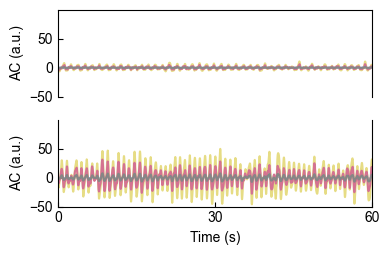

In [9]:
processor = SpectraDermaProcessor(sample_rate=50.0)
processor.load_data('../data/spectraderama_data_2025-03-25_sattac520S2.csv')
processor.swt_denoise(wavelet="db2", level=3, zero_levels=(1, 2, 3)).bandpass_filter(low_freq=0.5, high_freq=4.0, order=3)
timestamp, channels_ac = processor.get_data()

fig, (ax1, ax2) = plt.subplots(nrows=2, ncols=1, figsize=(4, 2.65))
fig.subplots_adjust(left=0.1, right=0.9, top=0.9, bottom=0.15)

for ch in range(channels_ac.shape[1]):
    y = channels_ac[:, ch]
    ax1.plot(timestamp, y, color=colors[ch], linewidth=1.5)
    ax2.plot(timestamp, y, color=colors[ch], linewidth=1.5)

ax1.set_xlim(*ppg_region_1)
ax2.set_xlim(*ppg_region_2)

# ax1.set_ylim(amplitude_limits[0], amplitude_limits[1])
# ax2.set_ylim(amplitude_limits[0], amplitude_limits[1])

# Ensure exactly three ticks on both axes for each subplot
for ax in (ax1, ax2):
    ax.tick_params(direction='in')
    ax.tick_params(axis='y')
    ax.set_ylabel('AC (a.u.)')

x1, x2 = ax.get_xlim()
ax2.set_xticks([x1, (x1 + x2) / 2, x2])
ax2.set_xticklabels([0, 30, 60])
ax2.set_xlabel('Time (s)')

ax1.set_ylim(-50, 100)
ax2.set_ylim(-50, 100)

ax1.spines['bottom'].set_visible(False)
ax2.spines['top'].set_visible(False)
ax1.set_xticks([])

ax1.set_yticks([-50, 0, 50])
ax2.set_yticks([-50, 0, 50])


plt.tight_layout()
# plt.savefig('../figures/fig3/mode_a_ac.png', dpi=600, bbox_inches='tight', transparent=True)

pos_ax1 = ax1.get_position()
pos_ax2 = ax2.get_position()

plt.show()

#### AC stats

In [10]:
from spectraderma_ppg_analyzer import SpectraDermaPPGAnalyzer

# Create analyzer instances for both regions
analyzer_1 = SpectraDermaPPGAnalyzer(sample_rate=50.0)
analyzer_2 = SpectraDermaPPGAnalyzer(sample_rate=50.0)

# Make sure we have AC data
processor.reset()
processor.swt_denoise(wavelet="db2", level=3, zero_levels=(1, 2, 3)).bandpass_filter(low_freq=0.5, high_freq=3, order=3)

# Load data into both analyzers
analyzer_1.load_data(processor)
analyzer_2.load_data(processor)

# Set regions
analyzer_1.set_region(ppg_region_start_1, ppg_region_end_1)
analyzer_2.set_region(ppg_region_start_2, ppg_region_end_2)

print("="*80)
print("COMPREHENSIVE PULSE ANALYSIS FOR BOTH REGIONS")
print("="*80)

# Analyze Region 1
print("\n" + "="*50)
print("REGION 1 ANALYSIS")
print("="*50)
pulse_data_1, peaks_1 = analyzer_1.find_peaks(reference_channel=2, tolerance_samples=15)
heart_rate_1 = analyzer_1.get_heart_rate()  # Fixed: no parameter needed
print(f"Found {len(peaks_1)} peaks, Heart Rate: {heart_rate_1:.1f} BPM")

# Analyze Region 2  
print("\n" + "="*50)
print("REGION 2 ANALYSIS")
print("="*50)
pulse_data_2, peaks_2 = analyzer_2.find_peaks(reference_channel=2, tolerance_samples=15)
heart_rate_2 = analyzer_2.get_heart_rate()  # Fixed: no parameter needed
print(f"Found {len(peaks_2)} peaks, Heart Rate: {heart_rate_2:.1f} BPM")

COMPREHENSIVE PULSE ANALYSIS FOR BOTH REGIONS

REGION 1 ANALYSIS
Found 44 peaks, Heart Rate: 65.9 BPM

REGION 2 ANALYSIS
Found 56 peaks, Heart Rate: 85.1 BPM



PEAK VISUALIZATION

Region 1 Visualization:


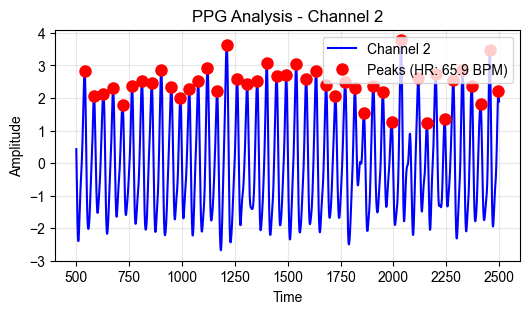


Region 2 Visualization:


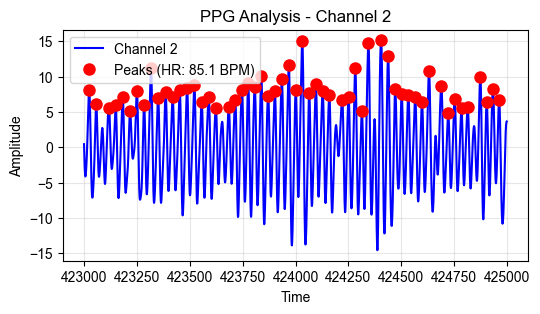

In [11]:
print("\n" + "="*60)
print("PEAK VISUALIZATION")
print("="*60)

# Plot peaks for both regions using the simplified analyzer
if len(peaks_1) > 0:
    print("\nRegion 1 Visualization:")
    analyzer_1.plot_peaks(channel_idx=2)

if len(peaks_2) > 0:
    print("\nRegion 2 Visualization:")
    analyzer_2.plot_peaks(channel_idx=2)

#### segmentation

REGION 1 - OVERLAID WAVEFORM SEGMENTS


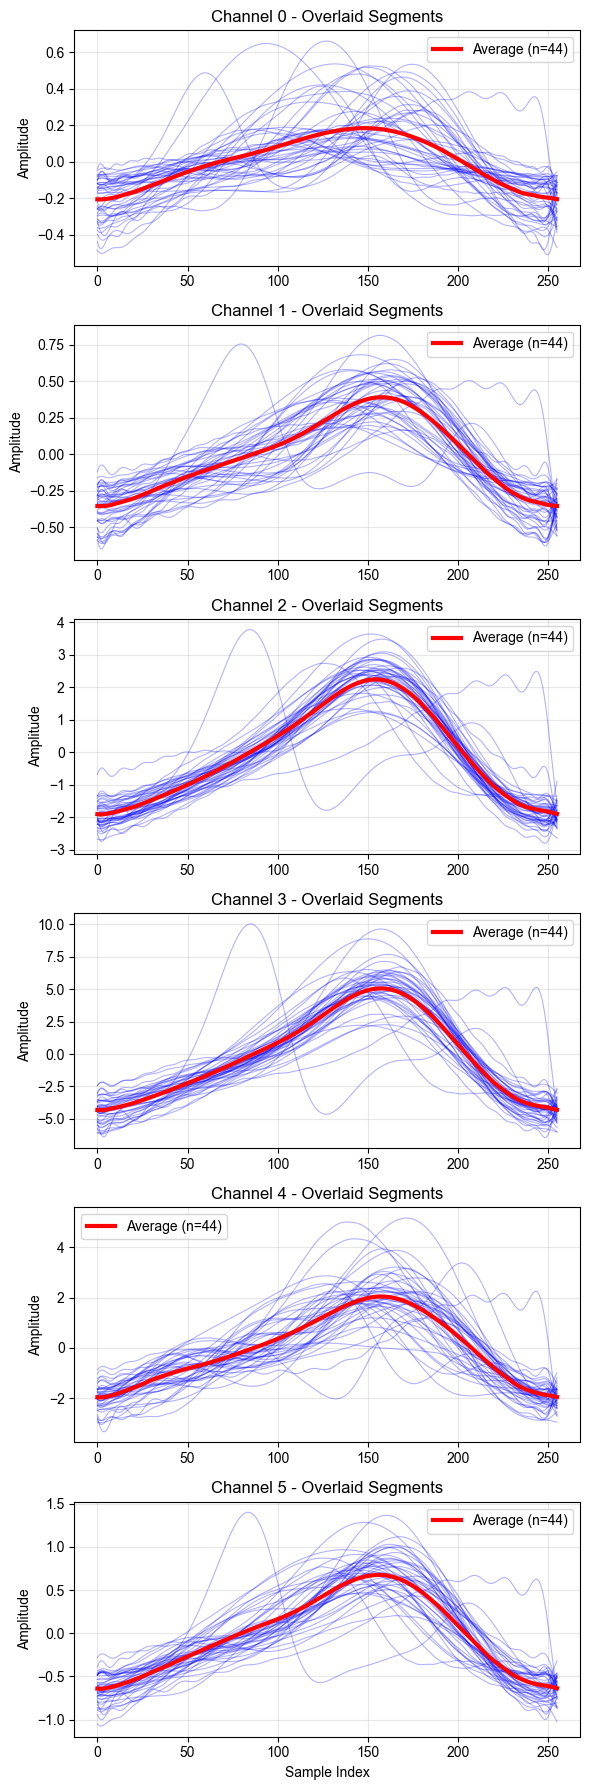

In [12]:
# Plot overlaid segments for Region 1
print("="*60)
print("REGION 1 - OVERLAID WAVEFORM SEGMENTS")
print("="*60)

analyzer_1.segment()
analyzer_1.plot_segments()

REGION 2 - OVERLAID WAVEFORM SEGMENTS


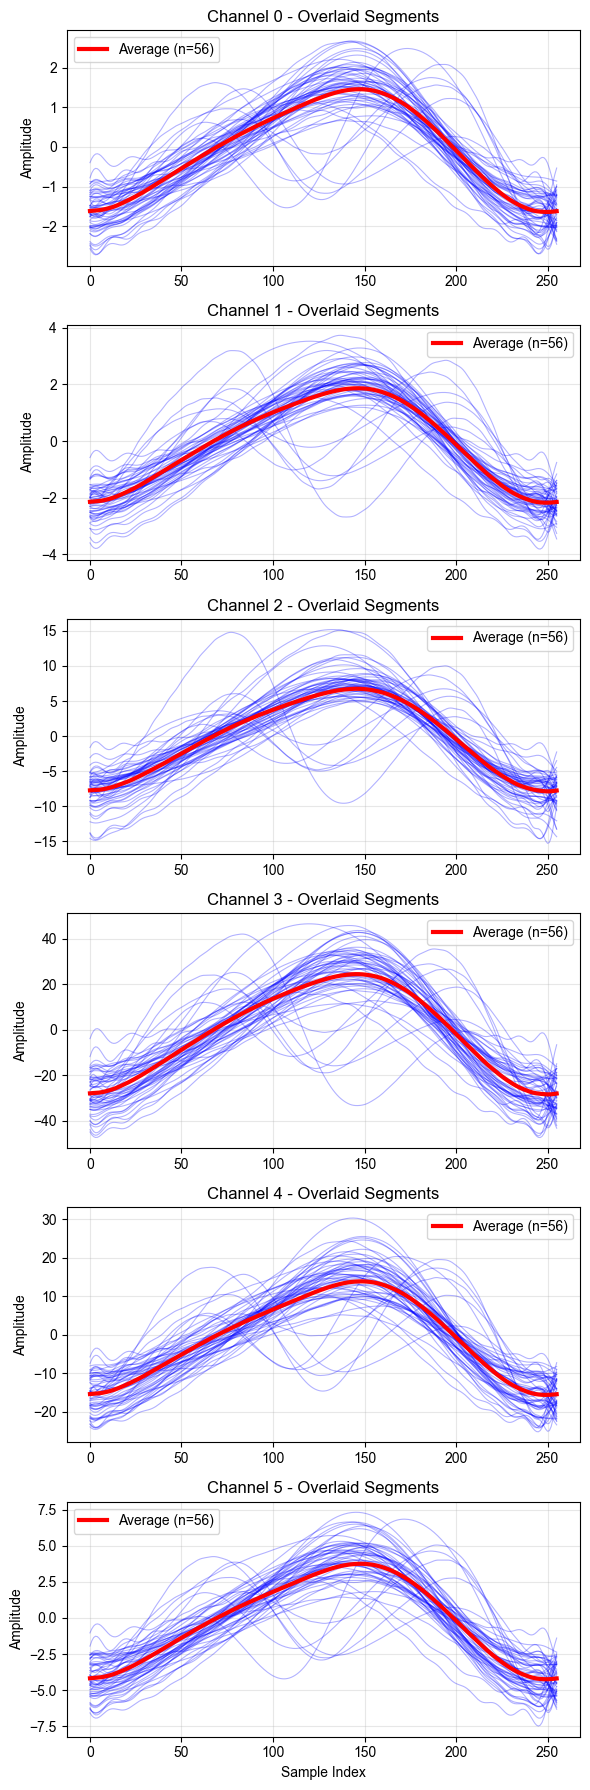

In [ ]:
# Plot overlaid segments for Region 1
print("="*60)
print("REGION 2 - OVERLAID WAVEFORM SEGMENTS")
print("="*60)

analyzer_2.segment()
analyzer_2.plot_segments()

##### save segments

In [19]:
analyzer_1.compile(save_path="../data/ppg_segments/520S2/normal.pt")
analyzer_2.compile(save_path="../data/ppg_segments/520S2/alcohol.pt")

Compiled segments saved to '../data/ppg_segments/520S2/normal.pt'
Shape: torch.Size([44, 256, 6]) (N=44, T=256, C=6)
Data type: torch.float32
Compiled segments saved to '../data/ppg_segments/520S2/alcohol.pt'
Shape: torch.Size([56, 256, 6]) (N=56, T=256, C=6)
Data type: torch.float32


tensor([[[ -0.9291,  -1.3002,  -4.1446, -16.3792,  -9.0866,  -2.5513],
         [ -0.8825,  -1.2356,  -3.9131, -15.7758,  -8.6616,  -2.4621],
         [ -0.8529,  -1.1957,  -3.7740, -15.3954,  -8.4022,  -2.4041],
         ...,
         [ -1.1533,  -1.6168,  -5.2964, -19.2990, -11.1854,  -2.9745],
         [ -1.0678,  -1.4955,  -4.8547, -18.1848, -10.3813,  -2.8137],
         [ -0.9917,  -1.3880,  -4.4633, -17.1936,  -9.6684,  -2.6702]],

        [[ -1.5309,  -2.1307,  -7.1401, -23.9836, -14.5543,  -3.6501],
         [ -1.5510,  -2.1917,  -7.3672, -24.1495, -14.8707,  -3.6929],
         [ -1.5521,  -2.1927,  -7.4118, -24.1019, -14.9087,  -3.6852],
         ...,
         [ -1.3892,  -1.6955,  -5.7077, -22.5316, -12.4347,  -3.3019],
         [ -1.4427,  -1.8569,  -6.2295, -23.0961, -13.2212,  -3.4347],
         [ -1.4929,  -2.0125,  -6.7397, -23.6121, -13.9744,  -3.5589]],

        [[ -1.3285,  -1.5329,  -5.2070, -21.8717, -11.5785,  -3.1538],
         [ -1.3612,  -1.5670,  -5.3634, -22.2

#### t-test

In [48]:
from scipy import stats
import matplotlib.colors as mcolors
import numpy as np

def add_significance_bracket(ax, x1, x2, y, p_value, height_offset=0.1):
    """Add significance bracket to plot only if significant"""
    # Only add bracket if significant
    if p_value < 0.05:
        # Determine significance level
        if p_value < 0.001:
            sig_text = '***'
        elif p_value < 0.01:
            sig_text = '**'
        else:
            sig_text = '*'
        
        # Draw bracket
        bracket_height = y + height_offset
        ax.plot([x1, x1, x2, x2], [y, bracket_height, bracket_height, y], 'k-', linewidth=1)
        
        # Add significance text
        ax.text((x1 + x2) / 2, bracket_height + 0.02, sig_text, 
                ha='center', va='bottom', fontsize=12, fontweight='bold')
        
        return bracket_height + 0.05
    else:
        # Return original y position if not significant (no bracket added)
        return y

def make_color_brighter(color, factor=1.5):
    """
    Make a color brighter by multiplying RGB values by a factor.
    
    Args:
        color: RGB color (as tuple, list, or array)
        factor: Brightness multiplication factor
    
    Returns:
        numpy array of brighter RGB values, clipped to [0,1]
    """
    
    # Convert to numpy array and ensure it's RGB (not RGBA)
    rgb = mcolors.to_rgb(color)  # Take only RGB components
    rgb = np.array(rgb)
    
    # Multiply by factor and clip to valid range [0, 1]
    brighter_rgb = np.clip(rgb * factor, 0, 1)
    
    return brighter_rgb

wavelengths = ['415', '480', '555', '590', '680', '910']

##### violin plot 1: peak height

Peak Height Analysis:
Ch    Normal (mean±std)    Alcohol (mean±std)   p-value   Sig
-----------------------------------------------------------------
Ch0   0.29±0.17      1.68±0.47      0.0000   ***
Ch1   0.45±0.15      2.23±0.56      0.0000   ***
Ch2   2.44±0.54      8.08±2.37      0.0000   ***
Ch3   5.54±1.57      28.96±8.21      0.0000   ***
Ch4   2.43±0.97      15.91±4.95      0.0000   ***
Ch5   0.78±0.24      4.33±1.27      0.0000   ***


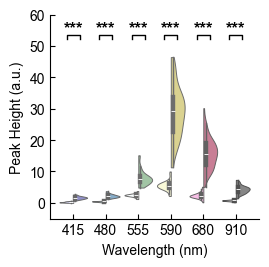

In [49]:
# Prepare data for seaborn
plot_data = []
significance_tests = []

print("Peak Height Analysis:")
print("Ch    Normal (mean±std)    Alcohol (mean±std)   p-value   Sig")
print("-" * 65)

for ch in range(6):
    # Extract data
    data1 = pulse_data_1[:, 0, ch][~np.isnan(pulse_data_1[:, 0, ch])]
    data2 = pulse_data_2[:, 0, ch][~np.isnan(pulse_data_2[:, 0, ch])]
    
    # Add to plot data in format for seaborn
    for val in data1:
        plot_data.append({'Height': val, 'Channel': wavelengths[ch], 'Condition': 'Normal'})
    
    for val in data2:
        plot_data.append({'Height': val, 'Channel': wavelengths[ch], 'Condition': 'Alcohol'})
    
    # Statistical test
    if len(data1) > 1 and len(data2) > 1:
        _, p_value = stats.ttest_ind(data1, data2, equal_var=False)
        is_sig = p_value < 0.05
        sig_text = '***' if p_value < 0.001 else '**' if p_value < 0.01 else '*' if p_value < 0.05 else 'ns'
        
        significance_tests.append({'channel': ch, 'p_value': p_value, 'is_significant': is_sig})
        print(f"Ch{ch}   {np.mean(data1):.2f}±{np.std(data1):.2f}      {np.mean(data2):.2f}±{np.std(data2):.2f}      {p_value:.4f}   {sig_text}")
    else:
        significance_tests.append({'channel': ch, 'p_value': None, 'is_significant': False})
        print(f"Ch{ch}   Insufficient data")

# Convert to DataFrame
plot_df = pd.DataFrame(plot_data)

# Create the plot using seaborn
fig, ax = plt.subplots(figsize=(2.7, 2.65))

# Create split violin plot
for idx, wl in enumerate(wavelengths):
    subset = plot_df[plot_df['Channel'] == wl]
    base_col = colors[idx]
    norm_col = make_color_brighter(base_col, 1.6)
    sns.violinplot(
        data=subset,
        x='Channel',
        y='Height',
        hue='Condition',
        order=[wl],
        hue_order=['Normal', 'Alcohol'],
        split=True,
        inner='box',
        cut=0,
        density_norm='width',
        width=0.85,
        palette={'Normal': norm_col, 'Alcohol': base_col},
        ax=ax,
        linewidth=0.7
    )

# Remove legend from the last call (hidden later anyway)
if ax.legend_:
    ax.legend_.remove()


# Format plot
ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel('Peak Height (a.u.)')
ax.set_xticks(range(6))
ax.set_xticklabels(wavelengths)
ax.set_ylim(-5, 60)

# Add significance brackets positioned at 10% from the top of current ylim
y_min, y_max = ax.get_ylim()
y_range = y_max - y_min
bracket_top = y_max - 0.10 * y_range
bracket_thickness = 0.02 * y_range
bracket_base = bracket_top - bracket_thickness

for test in significance_tests:
    if test['is_significant'] and test['p_value'] is not None:
        ch = test['channel']
        add_significance_bracket(
            ax,
            ch - 0.2,
            ch + 0.2,
            bracket_base,
            test['p_value'],
            height_offset=bracket_thickness
        )

ax.tick_params(direction='in')
ax.spines[['top', 'right']].set_visible(False)
ax.legend().set_visible(False)

pos_violin_ax = ax.get_position()
# plt.savefig('../figures/fig3/violin_peak_heights.png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

###### NOTE: fig3 axis position

In [ ]:
# pos_violin_ax

Bbox([[0.125, 0.10999999999999999], [0.9, 0.88]])

##### violin plot 2: peak interval

Peak Interval Analysis:
Ch    Normal (mean±std)    Alcohol (mean±std)   p-value   Sig
-----------------------------------------------------------------
Ch0   0.91±0.14      0.70±0.17      0.0000   ***
Ch1   0.91±0.12      0.71±0.17      0.0000   ***
Ch2   0.91±0.12      0.71±0.18      0.0000   ***
Ch3   0.91±0.12      0.70±0.17      0.0000   ***
Ch4   0.91±0.13      0.70±0.17      0.0000   ***
Ch5   0.91±0.12      0.70±0.17      0.0000   ***


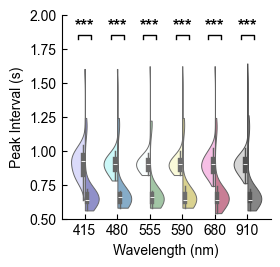

In [51]:
# Prepare data for seaborn
plot_data = []
significance_tests = []

print("Peak Interval Analysis:")
print("Ch    Normal (mean±std)    Alcohol (mean±std)   p-value   Sig")
print("-" * 65)

for ch in range(6):
    # Extract data
    data1 = pulse_data_1[:, 1, ch][~np.isnan(pulse_data_1[:, 1, ch])]
    data2 = pulse_data_2[:, 1, ch][~np.isnan(pulse_data_2[:, 1, ch])]
    
    # Add to plot data in format for seaborn
    for val in data1:
        plot_data.append({'Interval': val, 'Channel': wavelengths[ch], 'Condition': 'Normal'})
    
    for val in data2:
        plot_data.append({'Interval': val, 'Channel': wavelengths[ch], 'Condition': 'Alcohol'})
    
    # Statistical test
    if len(data1) > 1 and len(data2) > 1:
        _, p_value = stats.ttest_ind(data1, data2, equal_var=False)
        is_sig = p_value < 0.05
        sig_text = '***' if p_value < 0.001 else '**' if p_value < 0.01 else '*' if p_value < 0.05 else 'ns'
        
        significance_tests.append({'channel': ch, 'p_value': p_value, 'is_significant': is_sig})
        print(f"Ch{ch}   {np.mean(data1):.2f}±{np.std(data1):.2f}      {np.mean(data2):.2f}±{np.std(data2):.2f}      {p_value:.4f}   {sig_text}")
    else:
        significance_tests.append({'channel': ch, 'p_value': None, 'is_significant': False})
        print(f"Ch{ch}   Insufficient data")

# Convert to DataFrame
plot_df = pd.DataFrame(plot_data)

# Create the plot using seaborn
fig, ax = plt.subplots(figsize=(2.7, 2.65))

# Create split violin plot
for idx, wl in enumerate(wavelengths):
    subset = plot_df[plot_df['Channel'] == wl]
    base_col = colors[idx]
    norm_col = make_color_brighter(base_col, 1.6)
    sns.violinplot(
        data=subset,
        x='Channel',
        y='Interval',
        hue='Condition',
        order=[wl],
        hue_order=['Normal', 'Alcohol'],
        split=True,
        inner='box',
        cut=0,
        density_norm='width',
        width=0.85,
        palette={'Normal': norm_col, 'Alcohol': base_col},
        ax=ax,
        linewidth=0.7
    )

# Remove legend from the last call (hidden later anyway)
if ax.legend_:
    ax.legend_.remove()


# Format plot
ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel('Peak Interval (s)')
ax.set_xticks(range(6))
ax.set_xticklabels(wavelengths)
ax.set_ylim(0.5, 2)

# Add significance brackets positioned at 10% from the top of current ylim
y_min, y_max = ax.get_ylim()
y_range = y_max - y_min
bracket_top = y_max - 0.10 * y_range
bracket_thickness = 0.02 * y_range
bracket_base = bracket_top - bracket_thickness

for test in significance_tests:
    if test['is_significant'] and test['p_value'] is not None:
        ch = test['channel']
        add_significance_bracket(
            ax,
            ch - 0.2,
            ch + 0.2,
            bracket_base,
            test['p_value'],
            height_offset=bracket_thickness
        )

ax.tick_params(direction='in')
ax.spines[['top', 'right']].set_visible(False)
ax.legend().set_visible(False)

ax.set_position(pos_violin_ax)
# plt.savefig('../figures/fig3/violin_peak_intervals.png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

##### violin plot 3: peak width

Peak Width Analysis:
Ch    Normal (mean±std)    Alcohol (mean±std)   p-value   Sig
-----------------------------------------------------------------
Ch0   0.33±0.11      0.32±0.05      0.7435   ns
Ch1   0.36±0.08      0.33±0.09      0.0442   *
Ch2   0.36±0.06      0.32±0.04      0.0001   ***
Ch3   0.36±0.05      0.33±0.09      0.0519   ns
Ch4   0.37±0.09      0.32±0.05      0.0013   **
Ch5   0.37±0.06      0.32±0.05      0.0001   ***


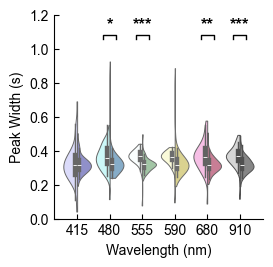

In [52]:
# Prepare data for seaborn
plot_data = []
significance_tests = []

print("Peak Width Analysis:")
print("Ch    Normal (mean±std)    Alcohol (mean±std)   p-value   Sig")
print("-" * 65)

for ch in range(6):
    # Extract data
    data1 = pulse_data_1[:, 2, ch][~np.isnan(pulse_data_1[:, 2, ch])]
    data2 = pulse_data_2[:, 2, ch][~np.isnan(pulse_data_2[:, 2, ch])]
    
    # Add to plot data in format for seaborn
    for val in data1:
        plot_data.append({'Width': val, 'Channel': wavelengths[ch], 'Condition': 'Normal'})
    
    for val in data2:
        plot_data.append({'Width': val, 'Channel': wavelengths[ch], 'Condition': 'Alcohol'})
    
    # Statistical test
    if len(data1) > 1 and len(data2) > 1:
        _, p_value = stats.ttest_ind(data1, data2, equal_var=False)
        is_sig = p_value < 0.05
        sig_text = '***' if p_value < 0.001 else '**' if p_value < 0.01 else '*' if p_value < 0.05 else 'ns'
        
        significance_tests.append({'channel': ch, 'p_value': p_value, 'is_significant': is_sig})
        print(f"Ch{ch}   {np.mean(data1):.2f}±{np.std(data1):.2f}      {np.mean(data2):.2f}±{np.std(data2):.2f}      {p_value:.4f}   {sig_text}")
    else:
        significance_tests.append({'channel': ch, 'p_value': None, 'is_significant': False})
        print(f"Ch{ch}   Insufficient data")

# Convert to DataFrame
plot_df = pd.DataFrame(plot_data)

# Create the plot using seaborn
fig, ax = plt.subplots(figsize=(2.7, 2.65))

# Create split violin plot
for idx, wl in enumerate(wavelengths):
    subset = plot_df[plot_df['Channel'] == wl]
    base_col = colors[idx]
    norm_col = make_color_brighter(base_col, 1.6)
    sns.violinplot(
        data=subset,
        x='Channel',
        y='Width',
        hue='Condition',
        order=[wl],
        hue_order=['Normal', 'Alcohol'],
        split=True,
        inner='box',
        cut=0,
        density_norm='width',
        width=0.85,
        palette={'Normal': norm_col, 'Alcohol': base_col},
        ax=ax,
        linewidth=0.7
    )

# Remove legend from the last call (hidden later anyway)
if ax.legend_:
    ax.legend_.remove()


# Format plot
ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel('Peak Width (s)')
ax.set_xticks(range(6))
ax.set_xticklabels(wavelengths)
ax.set_ylim(0, 1.2)

# Add significance brackets positioned at 10% from the top of current ylim
y_min, y_max = ax.get_ylim()
y_range = y_max - y_min
bracket_top = y_max - 0.10 * y_range
bracket_thickness = 0.02 * y_range
bracket_base = bracket_top - bracket_thickness

for test in significance_tests:
    if test['is_significant'] and test['p_value'] is not None:
        ch = test['channel']
        add_significance_bracket(
            ax,
            ch - 0.2,
            ch + 0.2,
            bracket_base,
            test['p_value'],
            height_offset=bracket_thickness
        )

ax.tick_params(direction='in')
ax.spines[['top', 'right']].set_visible(False)
ax.legend().set_visible(False)

ax.set_position(pos_violin_ax)
# plt.savefig('../figures/fig3/violin_peak_widths.png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

### DC

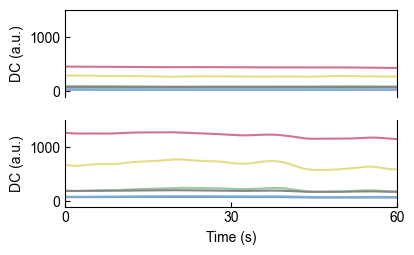

In [328]:
processor.reset()
processor.swt_denoise(wavelet="db2", level=3, zero_levels=(1, 2, 3)).lowpass_filter(cutoff=0.2, order=3)
timestamp, channels_dc = processor.get_data()


fig, (ax1, ax2) = plt.subplots(nrows=2, ncols=1, figsize=(4, 2.65))

for ch in range(channels_dc.shape[1]):
    y = channels_dc[:, ch]
    ax1.plot(timestamp, y, color=colors[ch], linewidth=1.5)
    ax2.plot(timestamp, y, color=colors[ch], linewidth=1.5)

ax1.set_xlim(*ppg_region_1)
ax2.set_xlim(*ppg_region_2)

# ax1.set_ylim(amplitude_limits[0], amplitude_limits[1])
# ax2.set_ylim(amplitude_limits[0], amplitude_limits[1])

for ax in (ax1, ax2):
    ax.tick_params(direction='in')
    ax.tick_params(axis='y')
    ax.set_ylabel('DC (a.u.)')

x1, x2 = ax.get_xlim()
ax2.set_xticks([x1, (x1 + x2) / 2, x2])
ax2.set_xticklabels([0, 30, 60])
ax2.set_xlabel('Time (s)')

ax1.set_ylim(-100, 1500)
ax2.set_ylim(-100, 1500)

ax1.spines['bottom'].set_visible(False)
ax2.spines['top'].set_visible(False)
ax1.set_xticks([])

ax1.set_position(pos_ax1)
ax2.set_position(pos_ax2)

# plt.tight_layout()
plt.savefig('../figures/fig3/mode_a_dc.png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

## dl classification

In [ ]:
from spectraderma_ppg_analyzer import PPGAnalyzer

analyzer = PPGAnalyzer(sample_rate=50.0)
analyzer.load_data(processor)
analyzer.set_region(ppg_region_start_1, ppg_region_end_1)

# Quick analysis example
pulse_data, peaks = analyzer.find_peaks()
heart_rate = analyzer.get_heart_rate(pulse_data)
print(f"Quick analysis: {len(peaks)} peaks, HR: {heart_rate:.1f} BPM")

# 555S1

In [60]:
processor.load_data('../data/spectraderama_data_2025-03-26_sattac555S1.csv')

# Get raw data for reference
timestamp, channels = processor.get_data()
print(f"Loaded data shape: {channels.shape}")
print(f"First few rows:")
print(pd.DataFrame(channels[:5]))  # Show first few rows like data.head()

Loaded data shape: (343404, 6)
First few rows:
     0    1     2     3    4     5
0  2.0  5.0  13.0  14.0  8.0  14.0
1  2.0  5.0  13.0  14.0  8.0  14.0
2  2.0  5.0  13.0  14.0  8.0  14.0
3  2.0  4.0  12.0  14.0  8.0  13.0
4  2.0  4.0  12.0  14.0  8.0  13.0


In [61]:
# Use processor pipeline to get processed data
processor.swt_denoise(wavelet="db2", level=3, zero_levels=(1, 2, 3))
processor.bandpass_filter(low_freq=0.5, high_freq=3.0, order=3)

# Get processed data
timestamp, channels_swt_f = processor.get_data()
print(f"Processed data shape: {channels_swt_f.shape}")

Processed data shape: (343404, 6)


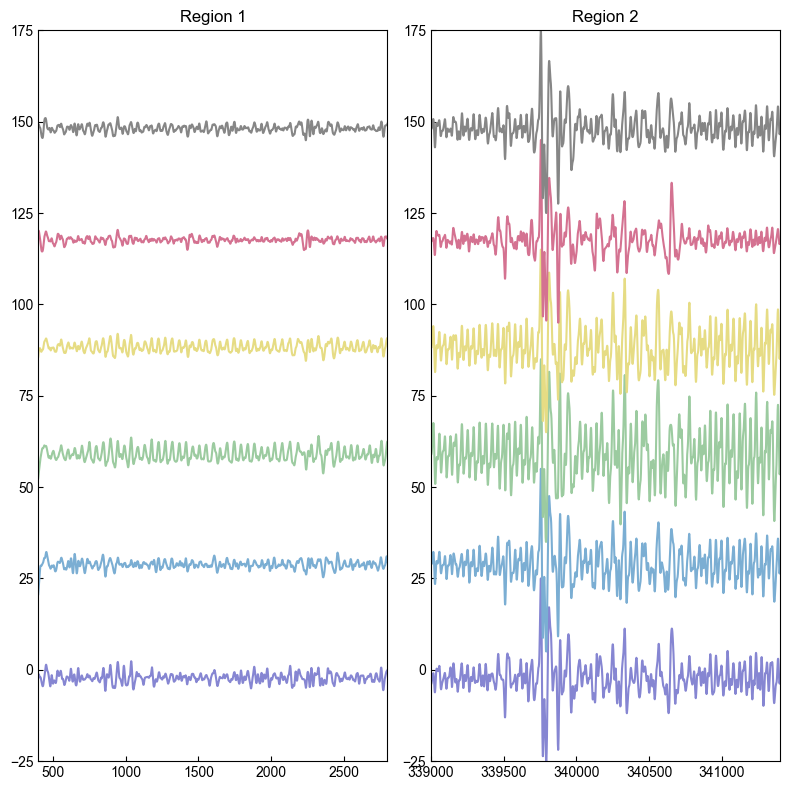

In [63]:
ppg_region_start_1 = 400
ppg_region_end_1 = 2800

ppg_region_start_2 = 339000
ppg_region_end_2 = 341400

ppg_region_1 = (ppg_region_start_1, ppg_region_end_1)
ppg_region_2 = (ppg_region_start_2, ppg_region_end_2)

amplitude_limits = (-25, 25)

processor.normalize(ppg_region_1, ppg_region_2, amplitude_limits=amplitude_limits)
timestamp, channels_swt_f_normalized = processor.get_data()

sample_rate = processor.sample_rate
y_offset = 30  # Small offset between channels

fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(8, 8))

for ch in range(channels_swt_f_normalized.shape[1]):
    y = channels_swt_f_normalized[:, ch] + ch * y_offset
    ax1.plot(timestamp, y, color=colors[ch], linewidth=1.5)
    ax2.plot(timestamp, y, color=colors[ch], linewidth=1.5)

ax1.set_xlim(*ppg_region_1)
ax2.set_xlim(*ppg_region_2)

ax1.set_ylim(amplitude_limits[0], amplitude_limits[1] + 5 * y_offset)
ax2.set_ylim(amplitude_limits[0], amplitude_limits[1] + 5 * y_offset)

ax1.set_title("Region 1")
ax2.set_title("Region 2")

for ax in (ax1, ax2):
    ax.tick_params(direction='in')

plt.tight_layout()
plt.show()

# 563S2

In [65]:
processor.load_data('../data/spectraderama_data_2025-03-24_sattac563S2.csv')

# Get raw data for reference
timestamp, channels = processor.get_data()
print(f"Loaded data shape: {channels.shape}")
print(f"First few rows:")
print(pd.DataFrame(channels[:5]))  # Show first few rows like data.head()

Loaded data shape: (31710, 6)
First few rows:
     0    1     2     3     4     5
0  2.0  6.0  18.0  18.0   9.0  13.0
1  2.0  6.0  18.0  18.0   9.0  13.0
2  2.0  6.0  18.0  18.0   9.0  13.0
3  2.0  6.0  17.0  19.0  10.0  13.0
4  3.0  6.0  17.0  19.0  10.0  13.0


In [66]:
# Use processor pipeline to get processed data
processor.swt_denoise(wavelet="db2", level=3, zero_levels=(1, 2, 3))
processor.bandpass_filter(low_freq=0.5, high_freq=2.0, order=3)

# Get processed data
timestamp, channels_swt_f = processor.get_data()
print(f"Processed data shape: {channels_swt_f.shape}")

Processed data shape: (31710, 6)


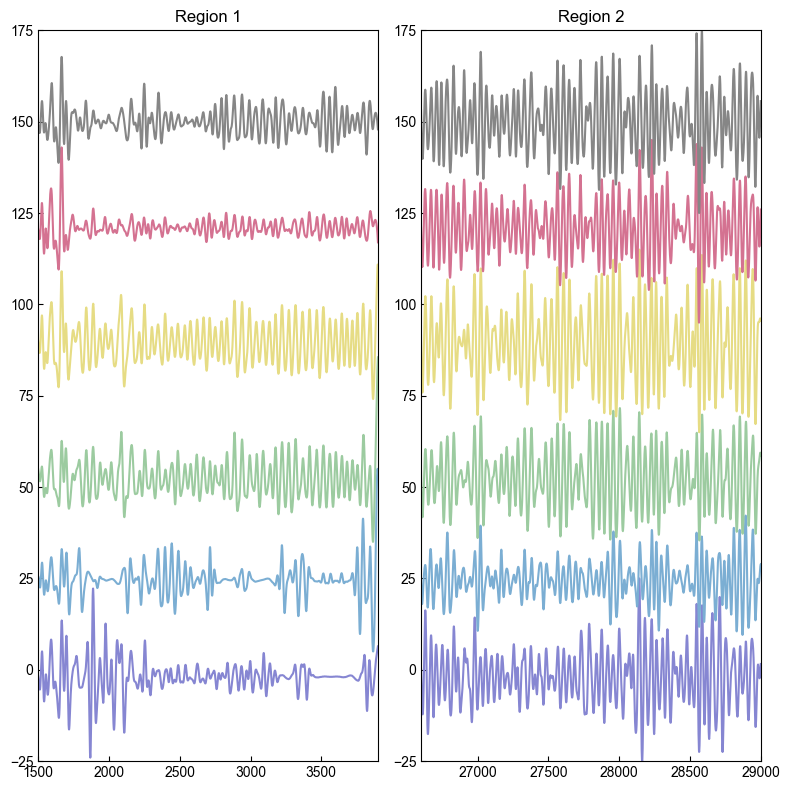

In [67]:
ppg_region_start_1 = 1500
ppg_region_end_1 = 3900

ppg_region_start_2 = 26600
ppg_region_end_2 = 29000

ppg_region_1 = (ppg_region_start_1, ppg_region_end_1)
ppg_region_2 = (ppg_region_start_2, ppg_region_end_2)

amplitude_limits = (-25, 25)

processor.normalize(ppg_region_1, ppg_region_2, amplitude_limits=amplitude_limits)
timestamp, channels_swt_f_normalized = processor.get_data()

sample_rate = processor.sample_rate
y_offset = 30  # Small offset between channels

fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(8, 8))

for ch in range(channels_swt_f_normalized.shape[1]):
    y = channels_swt_f_normalized[:, ch] + ch * y_offset
    ax1.plot(timestamp, y, color=colors[ch], linewidth=1.5)
    ax2.plot(timestamp, y, color=colors[ch], linewidth=1.5)

ax1.set_xlim(*ppg_region_1)
ax2.set_xlim(*ppg_region_2)

ax1.set_ylim(amplitude_limits[0], amplitude_limits[1] + 5 * y_offset)
ax2.set_ylim(amplitude_limits[0], amplitude_limits[1] + 5 * y_offset)

ax1.set_title("Region 1")
ax2.set_title("Region 2")

for ax in (ax1, ax2):
    ax.tick_params(direction='in')

plt.tight_layout()
plt.show()